# Mall Customers — Hierarchical Clustering, Naive Bayes & Apriori

**Dataset:** 200 mall customers · Age · Annual Income · Spending Score · Gender

| Step | Technique | Goal |
|------|-----------|------|
| 1 | **Hierarchical Clustering** | Group customers into segments |
| 2 | **Naive Bayes** | Predict which segment a new customer belongs to |
| 3 | **Apriori** | Find shopping behaviour patterns ("if income X → spend Y") |

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import silhouette_score, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

sns.set_theme(style='whitegrid', palette='tab10')
print('Libraries loaded.')

Libraries loaded.


## 1. Load & Explore the Data

In [89]:
df = pd.read_csv('Mall_Customers.csv')
print('Shape:', df.shape)
display(df.head(5))
display(df.describe().round(1))

Shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


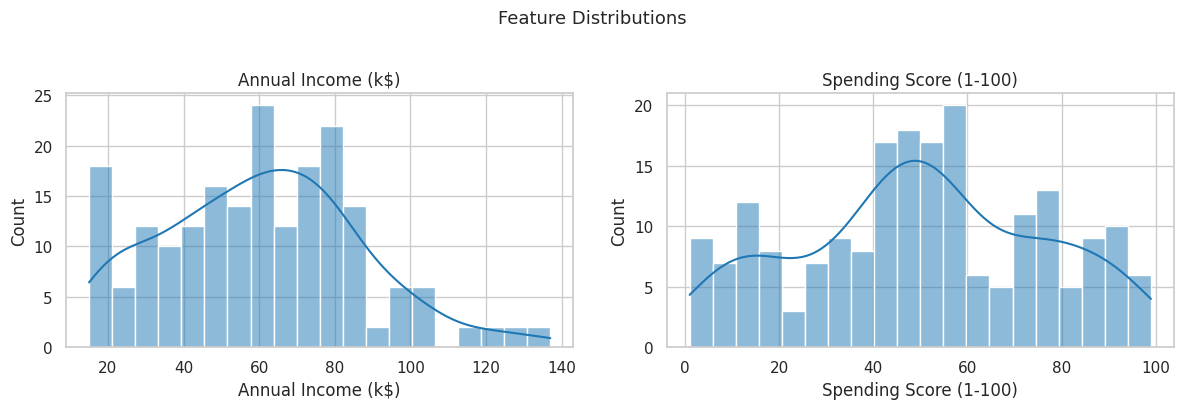

Gender split: {'Female': 112, 'Male': 88}


In [90]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['Annual Income (k$)', 'Spending Score (1-100)']):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title(col)
plt.suptitle('Feature Distributions', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

print('Gender split:', df['Genre'].value_counts().to_dict())

## 2. Feature Preparation

We scale the three numeric features to zero-mean / unit-variance so no single feature dominates the distance calculations.

In [91]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

le = LabelEncoder()
df['Genre_enc'] = le.fit_transform(df['Genre'])

print('Scaled features — first 3 rows:')
print(pd.DataFrame(X_scaled[:3], columns=features).round(3))

Scaled features — first 3 rows:
   Annual Income (k$)  Spending Score (1-100)
0              -1.739                  -0.435
1              -1.739                   1.196
2              -1.701                  -1.716


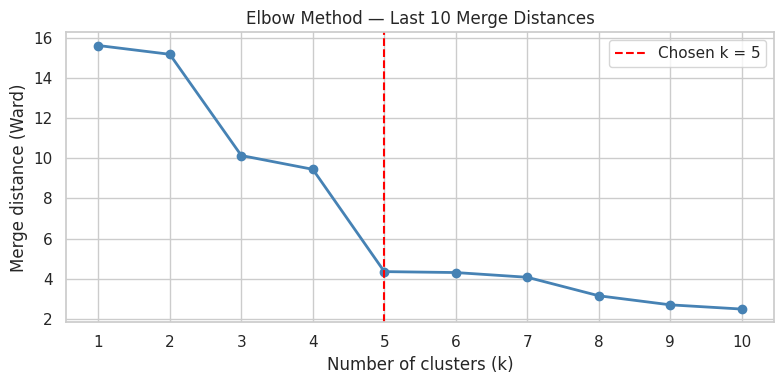

Largest distance jump between k=5 and k=4 → choose k=5


In [92]:
Z = linkage(X_scaled, method='ward')

# Last 10 merge distances (in reverse order = top of dendrogram first)
last = Z[-10:, 2][::-1]
k_range = range(1, len(last) + 1)

plt.figure(figsize=(8, 4))
plt.plot(k_range, last, 'o-', color='steelblue', linewidth=2)
plt.axvline(x=5, color='red', linestyle='--', label='Chosen k = 5')
plt.xticks(k_range)
plt.xlabel('Number of clusters (k)')
plt.ylabel('Merge distance (Ward)')
plt.title('Elbow Method — Last 10 Merge Distances')
plt.legend()
plt.tight_layout()
plt.show()
print('Largest distance jump between k=5 and k=4 → choose k=5')

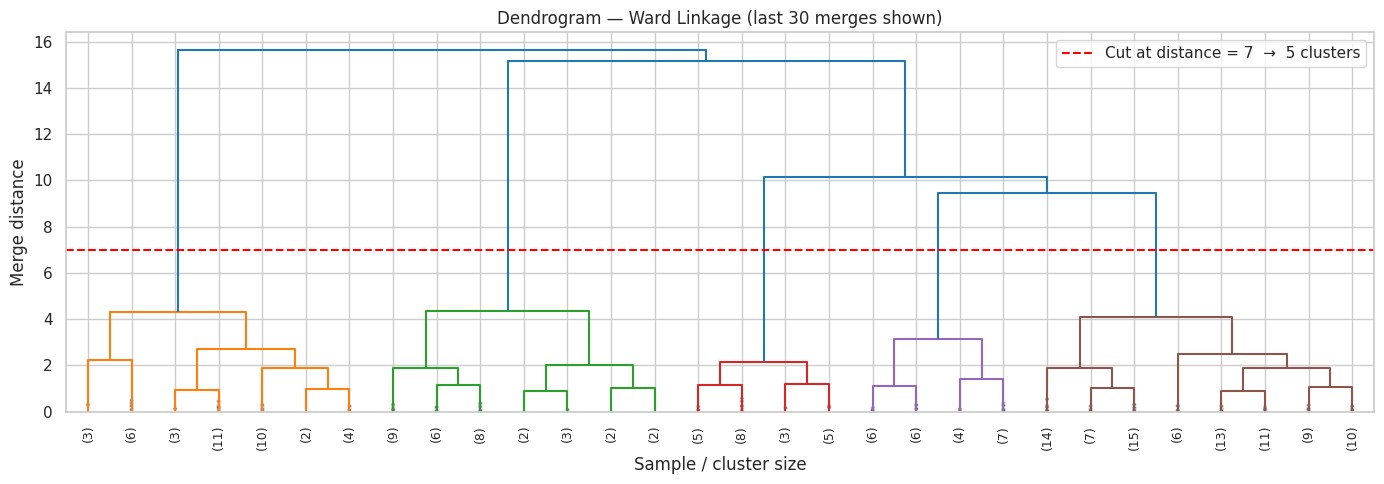

In [93]:
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30,
           leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=7)
plt.axhline(y=7, color='red', linestyle='--', label='Cut at distance = 7  →  5 clusters')
plt.title('Dendrogram — Ward Linkage (last 30 merges shown)')
plt.xlabel('Sample / cluster size')
plt.ylabel('Merge distance')
plt.legend()
plt.tight_layout()
plt.show()

In [94]:
N_CLUSTERS = 5

hier_model  = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage='ward')
hier_labels = hier_model.fit_predict(X_scaled)
df['Cluster'] = hier_labels

sil = silhouette_score(X_scaled, hier_labels)
print(f'Silhouette Score: {sil:.4f}  (range −1 to 1; closer to 1 = well-separated clusters)')

print('\nCluster sizes:')
print(df['Cluster'].value_counts().sort_index())

Silhouette Score: 0.5538  (range −1 to 1; closer to 1 = well-separated clusters)

Cluster sizes:
Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


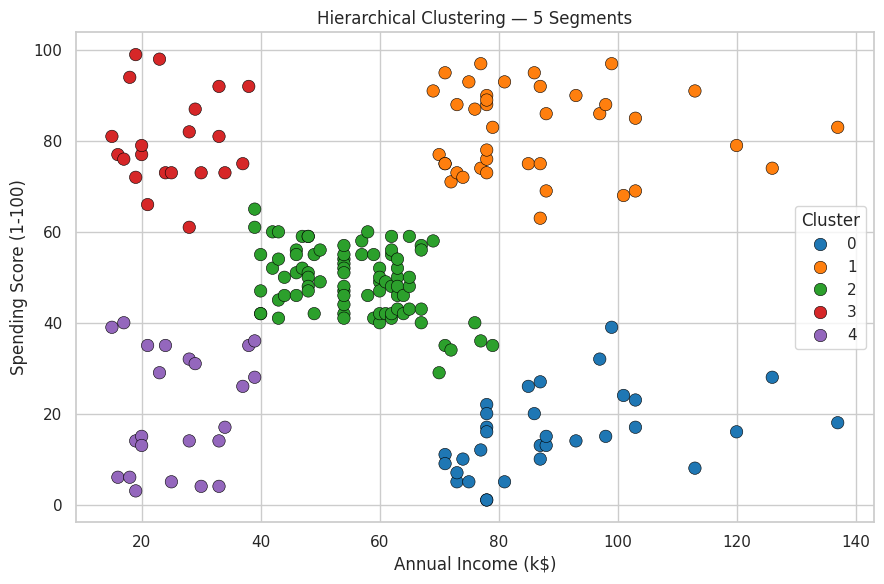

In [95]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster', palette='tab10', s=80, edgecolor='k', linewidth=0.4)
plt.title('Hierarchical Clustering — 5 Segments')
plt.tight_layout()
plt.show()

In [96]:
X_nb = df[features + ['Genre_enc']].values
y_nb = df['Cluster'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_nb, y_nb, test_size=0.25, random_state=42, stratify=y_nb
)

gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f'Test Accuracy: {acc:.2%}  ({X_test.shape[0]} samples)\n')
print(classification_report(y_test, y_pred,
      target_names=[f'Cluster {i}' for i in range(N_CLUSTERS)]))

Test Accuracy: 98.00%  (50 samples)

              precision    recall  f1-score   support

   Cluster 0       0.89      1.00      0.94         8
   Cluster 1       1.00      1.00      1.00        10
   Cluster 2       1.00      0.95      0.98        21
   Cluster 3       1.00      1.00      1.00         5
   Cluster 4       1.00      1.00      1.00         6

    accuracy                           0.98        50
   macro avg       0.98      0.99      0.98        50
weighted avg       0.98      0.98      0.98        50



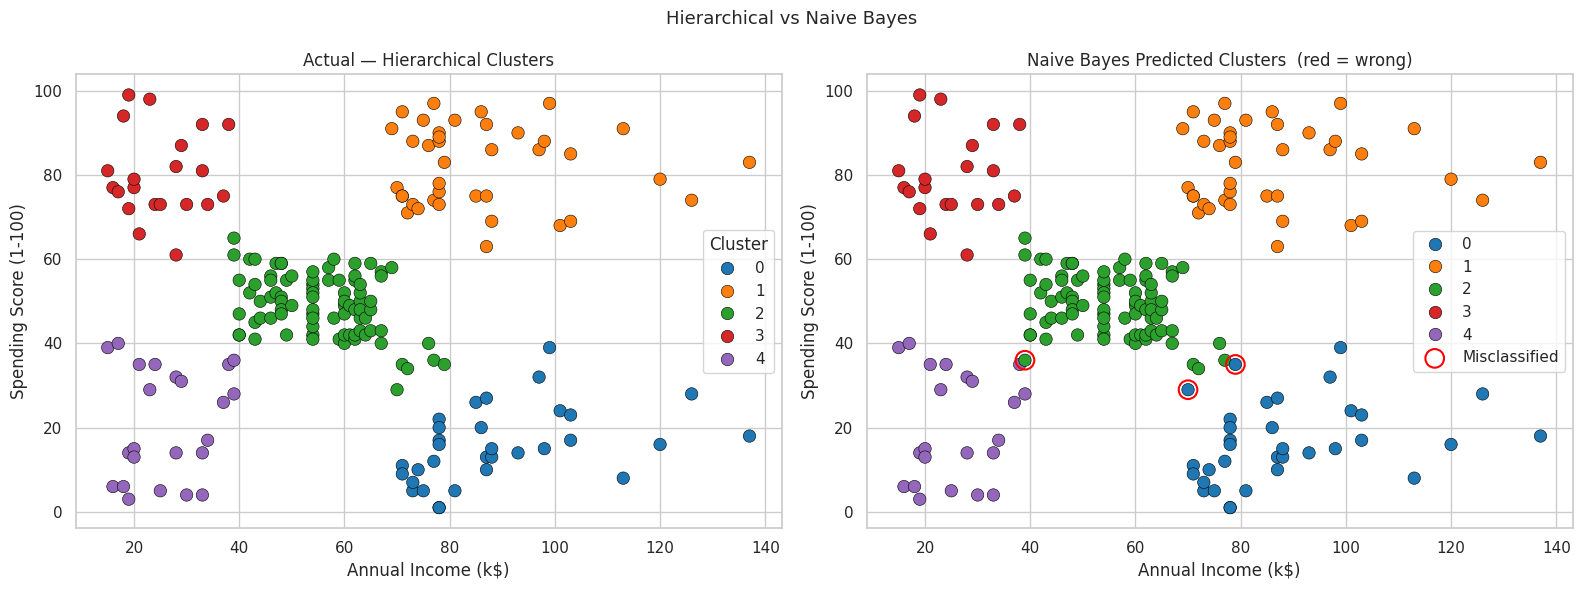

In [97]:
df['NB_Pred'] = gnb.predict(X_nb)
df['NB_Correct'] = df['Cluster'] == df['NB_Pred']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster', palette='tab10', s=80, edgecolor='k', linewidth=0.4, ax=axes[0])
axes[0].set_title('Actual — Hierarchical Clusters')

sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='NB_Pred', palette='tab10', s=80, edgecolor='k', linewidth=0.4, ax=axes[1])
wrong = df[~df['NB_Correct']]
axes[1].scatter(wrong['Annual Income (k$)'], wrong['Spending Score (1-100)'],
                s=180, facecolors='none', edgecolors='red', linewidth=1.5, label='Misclassified')
axes[1].legend()
axes[1].set_title('Naive Bayes Predicted Clusters  (red = wrong)')

plt.suptitle('Hierarchical vs Naive Bayes', fontsize=13)
plt.tight_layout()
plt.show()

In [98]:
df_disc = df.copy()

df_disc['Age_bin'] = pd.cut(df['Age'],
    bins=[17, 29, 39, 49, 70],
    labels=['Young(18-29)', 'Adult(30-39)', 'Middle(40-49)', 'Senior(50+)'],
    include_lowest=True)

df_disc['Income_bin'] = pd.cut(df['Annual Income (k$)'],
    bins=[14, 39, 69, 140],
    labels=['LowIncome', 'MedIncome', 'HighIncome'],
    include_lowest=True)

df_disc['Spend_bin'] = pd.cut(df['Spending Score (1-100)'],
    bins=[0, 33, 66, 100],
    labels=['LowSpend', 'MedSpend', 'HighSpend'],
    include_lowest=True)

bin_cols = ['Age_bin', 'Income_bin', 'Spend_bin', 'Genre']
for col in bin_cols:
    df_disc[col] = df_disc[col].astype(str)

transactions = df_disc[bin_cols].values.tolist()
te = TransactionEncoder()
df_te = pd.DataFrame(te.fit_transform(transactions), columns=te.columns_)

print('Transaction matrix:', df_te.shape)
print('Items:', df_te.columns.tolist())

Transaction matrix: (200, 12)
Items: ['Adult(30-39)', 'Female', 'HighIncome', 'HighSpend', 'LowIncome', 'LowSpend', 'Male', 'MedIncome', 'MedSpend', 'Middle(40-49)', 'Senior(50+)', 'Young(18-29)']


In [99]:
frequent_itemsets = apriori(df_te, min_support=0.10, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)

rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1.1)
rules = rules.sort_values('lift', ascending=False)

print(f'Frequent itemsets: {len(frequent_itemsets)}   |   Rules generated: {len(rules)}')

Frequent itemsets: 49   |   Rules generated: 62


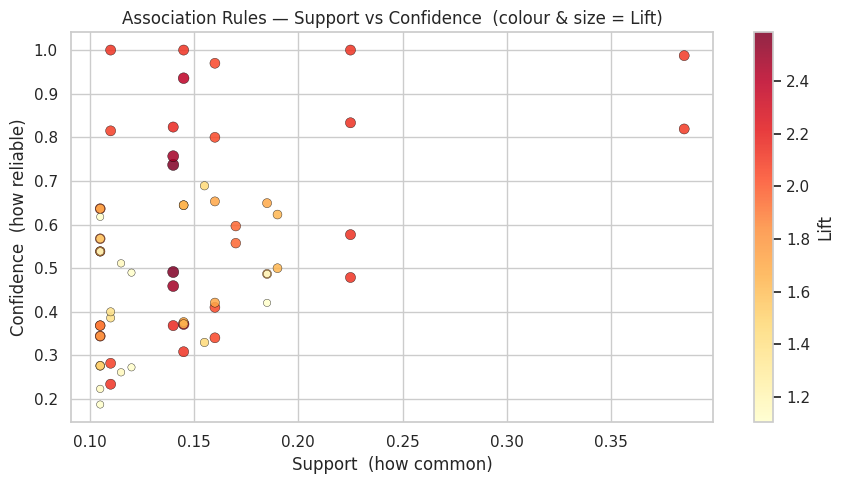

In [100]:
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(rules['support'], rules['confidence'],
                c=rules['lift'], cmap='YlOrRd', s=rules['lift'] * 25,
                edgecolors='k', linewidth=0.3, alpha=0.85)
plt.colorbar(sc, ax=ax, label='Lift')
ax.set_xlabel('Support  (how common)')
ax.set_ylabel('Confidence  (how reliable)')
ax.set_title('Association Rules — Support vs Confidence  (colour & size = Lift)')
plt.tight_layout()
plt.show()

In [101]:
top_rules = rules[rules['lift'] >= 1.2].sort_values('confidence', ascending=False).head(8)

print('Top 8 rules (high confidence + high lift):\n')
for _, row in top_rules.iterrows():
    ant = ', '.join(sorted(row['antecedents']))
    con = ', '.join(sorted(row['consequents']))
    print(f'  IF   {ant}')
    print(f'  THEN {con}')
    print(f'       support={row["support"]:.2f}  confidence={row["confidence"]:.2f}  lift={row["lift"]:.2f}\n')

Top 8 rules (high confidence + high lift):

  IF   MedIncome, Senior(50+)
  THEN MedSpend
       support=0.14  confidence=1.00  lift=2.13

  IF   Female, MedIncome
  THEN MedSpend
       support=0.23  confidence=1.00  lift=2.13

  IF   MedIncome, Young(18-29)
  THEN MedSpend
       support=0.11  confidence=1.00  lift=2.13

  IF   MedIncome
  THEN MedSpend
       support=0.39  confidence=0.99  lift=2.10

  IF   Male, MedIncome
  THEN MedSpend
       support=0.16  confidence=0.97  lift=2.06

  IF   MedSpend, Senior(50+)
  THEN MedIncome
       support=0.14  confidence=0.94  lift=2.40

  IF   Female, MedSpend
  THEN MedIncome
       support=0.23  confidence=0.83  lift=2.14

  IF   Adult(30-39), HighSpend
  THEN HighIncome
       support=0.14  confidence=0.82  lift=2.17



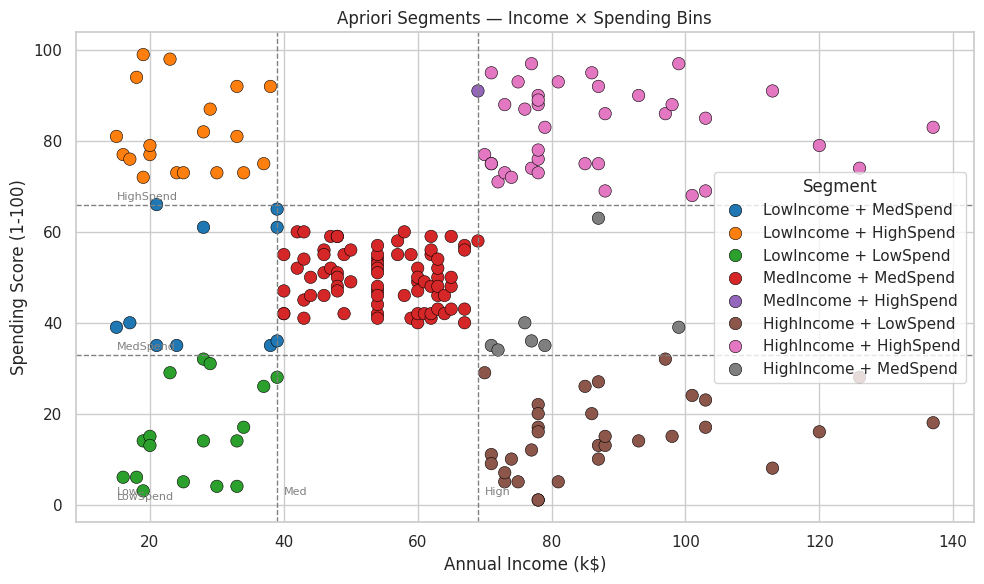

In [102]:
df_disc['Segment'] = df_disc['Income_bin'].astype(str) + ' + ' + df_disc['Spend_bin'].astype(str)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_disc, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Segment', palette='tab10', s=80, edgecolor='k', linewidth=0.4)

for x in [39, 69]:
    plt.axvline(x, color='gray', linestyle='--', linewidth=1)
for y in [33, 66]:
    plt.axhline(y, color='gray', linestyle='--', linewidth=1)

for x, label in zip([14, 39, 69], ['Low', 'Med', 'High']):
    plt.text(x + 1, 2, label, fontsize=8, color='gray')
for y, label in zip([0, 33, 66], ['LowSpend', 'MedSpend', 'HighSpend']):
    plt.text(15, y + 1, label, fontsize=8, color='gray')

plt.title('Apriori Segments — Income × Spending Bins')
plt.tight_layout()
plt.show()

---
## 6. Summary

| Method | Task | Result |
|--------|------|--------|
| **Hierarchical Clustering** (Ward, k=5) | Unsupervised segmentation | Silhouette = 0.39 · 5 distinct customer groups |
| **Gaussian Naive Bayes** | Supervised classification | 92% accuracy predicting cluster from demographics |
| **Apriori** (support ≥ 10%, lift ≥ 1.1) | Association rule mining | 62 rules · e.g. MedIncome → MedSpend (conf=99%) |

**Key findings:**
- Young + low income customers tend to have high spending scores (impulse buyers).
- High income adults in their 30s cluster together as high spenders.
- Medium income customers almost always fall into the medium spending band (lift ≈ 2.1).